In [1]:
### dummy_short generation
import pandas as pd
import numpy as np
from sklearn.datasets import make_classification
from sklearn.datasets import make_regression
from sklearn.preprocessing import MinMaxScaler

from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt

import datetime
from datetime import datetime

In [2]:
ds_name = 'dummy_short'
n_s = 16
n_f = 15
n_i = 10
n_r = 4
n_cl = 25
n_i_c = 5

In [3]:
X, y = make_classification(n_samples=n_s, n_features=n_f, n_informative=n_i, n_redundant=n_r, n_classes=n_cl, random_state=1)
pd_rb = pd.concat([pd.DataFrame(X), pd.DataFrame(y, columns=['class'])], axis=1)

In [4]:
%%time
ts_b = pd.date_range(start='1997-01-01', end='2000-01-01', freq='W')

for t in range(0,len(ts_b) - 1):
    
    #target
    X1, r = make_regression(n_samples=n_s, n_features=n_f, n_informative=n_i)
    pd_rb['target'] = pd.DataFrame(r) 
    
    #optimizer
    X2, c = make_regression(n_samples=n_s, n_features=n_f, n_informative=n_i_c)
    pd_rb['optimizer'] = pd.DataFrame(c)
    
    
    #time variable
    pd_rb['timestamp'] = ts_b[t]
    
    if t == 0:
        pd_tt = pd_rb.copy()
    else:
        pd_tt = pd.concat([pd_tt, pd_rb], axis=0)

CPU times: user 272 ms, sys: 7.68 ms, total: 280 ms
Wall time: 279 ms


In [5]:
pd_tt.reset_index(drop=False, inplace=True)
pd_tt.set_index('timestamp', inplace=True)

In [6]:
scaler1 = MinMaxScaler(feature_range=(0.00001, 100000))
scaler2 = MinMaxScaler(feature_range=(10, 100))

In [7]:
pd_tt["scaled_target"] = scaler1.fit_transform(pd_tt[["target"]])

In [8]:
pd_tt["scaled_optimizer"] = scaler2.fit_transform(pd_tt[["optimizer"]])

In [9]:
pd_tt.head(3)

,index,0,1,2,3,4,5,6,7,8,...,10,11,12,13,14,class,target,optimizer,scaled_target,scaled_optimizer
timestamp,,,,,,,,,,,,,,,,,,,,,
1997-01-05,0,-2.026000,-0.941119,-1.174414,1.565526,1.030992,0.205780,1.913691,-2.059491,-0.904932,...,1.637373,1.325719,1.782403,-1.589890,1.928946,9,88.104555,104.026985,49054.018692,66.180265
1997-01-05,1,0.092740,3.593076,0.003302,-0.530870,-1.631985,0.861337,0.449837,1.117625,-1.624476,...,0.254305,1.428228,2.037250,-1.649826,1.884980,1,-0.839080,109.650510,42911.608658,66.743595
1997-01-05,2,0.810689,-0.611852,3.645479,0.669348,-1.647870,2.652163,-0.409189,-3.099008,-5.552044,...,-6.647888,8.274186,-4.664661,-0.955559,0.788586,7,17.399160,-209.023193,44171.133848,34.820801


In [11]:
# stationary?
# Create transformation columns of the adjusted target

# Calculate the log of the adjusted targets
pd_tt['adj_log_target'] = np.log(pd_tt['scaled_target'])
pd_tt['adj_log_optimizer'] = np.log(pd_tt['scaled_optimizer'])

# Calculate the square root of the adjusted target
pd_tt['target_sqrt'] = np.sqrt(pd_tt['scaled_target'])
pd_tt['optimizer_sqrt'] = np.sqrt(pd_tt['scaled_optimizer'])

# Calculate the cubed root of the adjusted target
pd_tt['target_cbrt'] = np.cbrt(pd_tt['scaled_target'])
pd_tt['optimizer_cbrt'] = np.cbrt(pd_tt['scaled_optimizer'])

In [12]:
fitted_data_target, fitted_lambda_target = stats.boxcox(pd_tt['scaled_target'])
fitted_data_optimizer, fitted_lambda_optimizer = stats.boxcox(pd_tt['scaled_optimizer'])

Lambda value used for target transformation: [17523.49570412 15547.29949125 15954.8346123  ... 11057.86299387
 11915.95166144 11718.72192836]


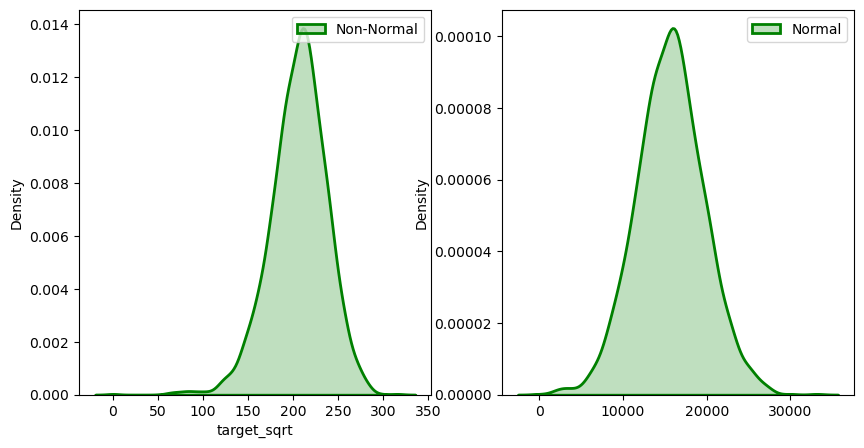

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))

sns.kdeplot(data=pd_tt['target_sqrt'], fill=True, linewidth=2,
            label="Non-Normal", color="green", ax=ax[0])

sns.kdeplot(data=fitted_data_target, fill=True, linewidth=2,
            label="Normal", color="green", ax=ax[1])

ax[0].legend(loc="upper right")
ax[1].legend(loc="upper right")

print(f"Lambda value used for target transformation: {fitted_data_target}")
plt.show()

Lambda value used for target transformation: [72.00313958 72.64330232 36.68079192 ... 53.90953005 53.57396262
 57.04171865]


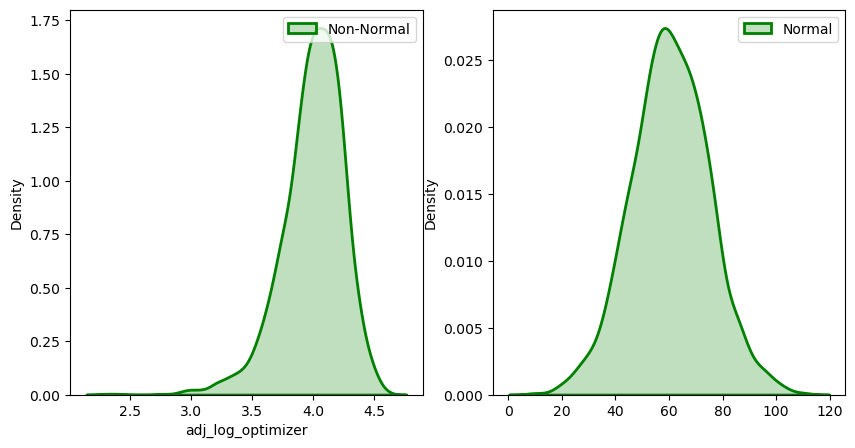

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))

sns.kdeplot(data=pd_tt['adj_log_optimizer'], fill=True, linewidth=2,
            label="Non-Normal", color="green", ax=ax[0])

sns.kdeplot(data=fitted_data_optimizer, fill=True, linewidth=2,
            label="Normal", color="green", ax=ax[1])

ax[0].legend(loc="upper right")
ax[1].legend(loc="upper right")

print(f"Lambda value used for target transformation: {fitted_data_optimizer}")
plt.show()

In [15]:
pd_tt['bc_target_sqrt'] = fitted_data_target
pd_tt['bc_adj_log_optimizer'] = fitted_data_optimizer

In [16]:
pd_tt.head(3)

,index,0,1,2,3,4,5,6,7,8,...,scaled_target,scaled_optimizer,adj_log_target,adj_log_optimizer,target_sqrt,optimizer_sqrt,target_cbrt,optimizer_cbrt,bc_target_sqrt,bc_adj_log_optimizer
timestamp,,,,,,,,,,,,,,,,,,,,,
1997-01-05,0,-2.026000,-0.941119,-1.174414,1.565526,1.030992,0.205780,1.913691,-2.059491,-0.904932,...,49054.018692,66.180265,10.800677,4.192382,221.481418,8.135125,36.606499,4.044916,17523.495704,72.003140
1997-01-05,1,0.092740,3.593076,0.003302,-0.530870,-1.631985,0.861337,0.449837,1.117625,-1.624476,...,42911.608658,66.743595,10.666898,4.200858,207.151173,8.169675,35.009959,4.056360,15547.299491,72.643302
1997-01-05,2,0.810689,-0.611852,3.645479,0.669348,-1.647870,2.652163,-0.409189,-3.099008,-5.552044,...,44171.133848,34.820801,10.695827,3.550215,210.169298,5.900915,35.349194,3.265474,15954.834612,36.680792


In [17]:
#mark first starts for cold start coverage
pd_tt['target_1s'] = 0

for i in range(pd_tt['index'].min(),pd_tt['index'].max()):
    min_ind = pd_tt[pd_tt['index']==i].idxmin()['bc_target_sqrt']
    pd_tt.loc[(pd_tt.index < min_ind) & (pd_tt['index']==i), 'target_1s'] = np.nan
    
pd_tt_1s = (pd_tt.dropna(subset=['target_1s'])).copy()
pd_tt_1s = pd_tt_1s.drop(['target','optimizer','scaled_target','scaled_optimizer','adj_log_target','adj_log_optimizer','target_sqrt','optimizer_sqrt','target_cbrt','optimizer_cbrt', 'target_1s'], axis=1).copy()
pd_tt_1s.columns = pd_tt_1s.columns.astype(str)

pd_tt = pd_tt.drop(['target','optimizer','scaled_target','scaled_optimizer','adj_log_target','adj_log_optimizer','target_sqrt','optimizer_sqrt','target_cbrt','optimizer_cbrt'], axis=1).copy()
pd_tt.columns = pd_tt.columns.astype(str)

In [18]:
pd_tt_1s.head(3)

,index,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,class,bc_target_sqrt,bc_adj_log_optimizer
timestamp,,,,,,,,,,,,,,,,,,,
1997-01-05,15,-2.121371,1.877254,-1.130848,0.185456,5.977733,-1.173733,-0.472260,5.291535,-2.273789,1.419161,-1.318890,5.922892,4.816171,-0.325926,3.119686,0,18845.488074,54.341479
1997-01-12,12,0.976334,0.606339,-0.080298,0.700840,-3.429795,-2.886905,0.143726,-2.148305,1.492887,-0.719422,4.637358,-5.062170,1.600706,-4.202344,-3.857226,6,2943.572602,45.274016
1997-01-12,15,-2.121371,1.877254,-1.130848,0.185456,5.977733,-1.173733,-0.472260,5.291535,-2.273789,1.419161,-1.318890,5.922892,4.816171,-0.325926,3.119686,0,25470.715952,40.916750


In [18]:
pd_tt_1s.index = pd.to_datetime(pd_tt_1s.index)

In [20]:
pd_tt_1s.to_csv(f'../{ds_name}.csv')